# 📘 5.6 Training Data Evaluation and Selection

### Deciding what evidence a regression model is allowed to learn from

A regression algorithm can only learn from the examples it receives. A sophisticated
model trained on unsuitable evidence can appear accurate during development and fail in
service.

This notebook treats data selection as an engineering design decision. We will audit a
pump-fleet dataset, identify information leakage, compare random, grouped and time-ordered
evaluation, use a safe preprocessing pipeline, and define checks for future deployment.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* connect the **intended prediction task** to the required training-data coverage;
* audit schema, units, missing values, duplicates and implausible observations;
* distinguish unusual but valid observations from recording errors;
* identify target leakage and preprocessing leakage;
* choose a random, grouped or time-ordered split to match the deployment question;
* use a scikit-learn `Pipeline` so preprocessing is learned from training data only;
* recognise distribution shift and unsupported operating conditions; and
* document a defensible data-selection decision.

### 🔗 Unit Learning Outcome Alignment

This notebook supports **LO1, LO2 and LO3** through method selection, reproducible model
development, and evaluation of performance, limitations and validity.

### 📚 Sources used in this notebook

* scikit-learn — [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)
* scikit-learn — [Cross-validation and data splitting](https://scikit-learn.org/stable/modules/cross_validation.html)
* scikit-learn — [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
* scikit-learn — [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)
* scikit-learn — [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
* Google for Developers — [Rules of Machine Learning](https://developers.google.com/machine-learning/guides/rules-of-ml/)
* NIST — [AI Risk Management Framework Playbook](https://airc.nist.gov/airmf-resources/playbook/)


## 📂 5.6.0 How to use this notebook

Run every code cell from top to bottom. No cell requires editing, typed input, internet
access or an external data file.

The example is deliberately designed to expose mistakes. The goal is not to obtain the
smallest possible error; it is to decide whether an error estimate answers the real
engineering question.


## 📂 5.6.1 Define the prediction task

Before selecting rows or features, define exactly what the model is intended to do. Start
by answering five questions:

1. **Unit of observation:** what real-world case does one sample, data point or row
   represent—for example, one experimental run, one component or one measurement at a
   particular time?
2. **Target:** what quantity is predicted, at what time, and in what units?
3. **Available inputs:** what will genuinely be known when the prediction is made?
4. **Deployment population:** which assets, sites, seasons and operating regions matter?
5. **Decision and cost:** how will the prediction be used, and what happens when it is
   wrong?

The answers can then be combined into a short **prediction contract**. The contract is not
a separate sixth item: it is a concise statement of Items 1–5 that guides row selection,
feature selection, data splitting and evaluation.

### Applying Questions 1–5 to the pump example

| Question | Answer for this example |
|---|---|
| 1. Unit of observation | One run of one physical pump; each row is one run and receives one prediction |
| 2. Target | Mean electrical power during that run, measured in kW |
| 3. Available inputs | Operating measurements available at the start of the run |
| 4. Deployment population | Initially, future runs from pumps represented in the monitored fleet; transfer to new pumps is tested separately |
| 5. Decision and cost | Support energy planning and equipment monitoring; inaccurate estimates may hide abnormal energy use or distort planning |

These answers produce the following prediction contract:

> At the start of a pump run, predict the mean electrical power in kW for that run using
> currently available operating measurements. The initial model will support future runs
> from pumps already represented in the monitored fleet. Transfer to previously unseen
> pumps will be evaluated separately. Prediction errors may affect energy planning and the
> detection of abnormal operation.

The contract immediately excludes measurements collected after the run. It also reminds us
that many rows may come from the same physical pump: they are separate run-level samples,
but they are not independent assets.


In [ ]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import (
    GroupShuffleSplit,
    TimeSeriesSplit,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

pd.set_option("display.precision", 3)


## 📂 5.6.2 Engineering example: a monitored pump fleet

Twelve nominally similar pumps are monitored over 70 days. Each row represents one run.
Manufacturing variation gives each pump a slightly different efficiency. Wear increases
with operating hours, and environmental conditions change over time.

The dataset is **synthetic and deterministic**. Its planted problems are known, which lets
us test whether an audit finds them. It is not performance data for a real pump.


In [ ]:
rng = np.random.default_rng(5602)
n_pumps = 12
days = pd.date_range("2026-01-05", periods=70, freq="D")
pump_ids = [f"P{number:02d}" for number in range(1, n_pumps + 1)]
efficiency_offset = dict(zip(pump_ids, rng.normal(0.0, 0.045, n_pumps)))

records = []
event_number = 0
for pump_number, pump_id in enumerate(pump_ids):
    operating_hours = rng.uniform(300.0, 1800.0)
    for day_number, timestamp in enumerate(days):
        for run_number in range(2):
            event_number += 1
            season_signal = np.sin(2 * np.pi * day_number / 70)
            flow_m3h = np.clip(
                285 + 70 * season_signal + rng.normal(0, 58), 105, 480
            )
            pressure_rise_kpa = np.clip(
                310 - 0.28 * (flow_m3h - 285) + rng.normal(0, 24), 165, 430
            )
            inlet_temp_c = 23 + 7 * season_signal + rng.normal(0, 1.8)
            run_duration_h = rng.uniform(1.0, 5.5)
            operating_hours += run_duration_h
            wear = 0.000018 * operating_hours
            vibration_mm_s = np.clip(
                1.1 + 11 * wear + rng.normal(0, 0.22), 0.45, None
            )
            # A fleet-wide late-period degradation creates a realistic future shift.
            late_period_degradation = 0.0025 * max(day_number - 48, 0)
            efficiency = np.clip(
                0.78
                + efficiency_offset[pump_id]
                - wear
                - late_period_degradation
                - 0.000035 * (flow_m3h - 300) ** 2
                - 0.0018 * np.maximum(inlet_temp_c - 27, 0),
                0.54,
                0.86,
            )
            hydraulic_power_kw = flow_m3h * pressure_rise_kpa / 3600
            power_kw = (
                hydraulic_power_kw / efficiency
                + 2.8
                + rng.normal(0, 0.65)
            )

            records.append({
                "event_id": f"E{event_number:05d}",
                "timestamp": timestamp + pd.Timedelta(hours=8 + 4 * run_number),
                "pump_id": pump_id,
                "flow_m3h": flow_m3h,
                "pressure_rise_kpa": pressure_rise_kpa,
                "inlet_temp_c": inlet_temp_c,
                "vibration_mm_s": vibration_mm_s,
                "operating_hours": operating_hours,
                "run_duration_h": run_duration_h,
                "mean_power_kw": power_kw,
                # Recorded after the run: unavailable at prediction time.
                "post_run_energy_kwh": power_kw * run_duration_h + rng.normal(0, 0.15),
            })

reference_data = pd.DataFrame(records)

# Realistic missing sensor transmissions.
for column, fraction in {"inlet_temp_c": 0.025, "vibration_mm_s": 0.04}.items():
    missing_index = rng.choice(reference_data.index, int(fraction * len(reference_data)), replace=False)
    reference_data.loc[missing_index, column] = np.nan

# The received file contains repeated uploads and two unit-entry problems.
duplicate_rows = reference_data.sample(180, random_state=56)
received_data = pd.concat([reference_data, duplicate_rows], ignore_index=True)
eligible_flow_index = received_data.index[received_data["flow_m3h"] < 350]
bad_flow_index = rng.choice(eligible_flow_index, 7, replace=False)
received_data.loc[bad_flow_index, "flow_m3h"] /= 3.6  # L/s values stored as m³/h
eligible_temperature_index = received_data.index[
    received_data["inlet_temp_c"].notna() & ~received_data.index.isin(bad_flow_index)
]
bad_temperature_index = rng.choice(eligible_temperature_index, 6, replace=False)
received_data.loc[bad_temperature_index, "inlet_temp_c"] = (
    received_data.loc[bad_temperature_index, "inlet_temp_c"] * 9 / 5 + 32
)

received_data.head()


,event_id,timestamp,pump_id,flow_m3h,pressure_rise_kpa,inlet_temp_c,vibration_mm_s,operating_hours,run_duration_h,mean_power_kw,post_run_energy_kwh
0,E00001,2026-01-05 08:00:00,P01,284.205,287.979,19.831,1.327,1676.015,3.054,34.123,104.098
1,E00002,2026-01-05 12:00:00,P01,307.142,303.982,23.395,1.463,1678.197,2.182,36.104,78.853
2,E00003,2026-01-06 08:00:00,P01,381.213,248.431,22.408,1.467,1682.175,3.978,51.347,204.251
3,E00004,2026-01-06 12:00:00,P01,280.559,254.045,23.191,1.359,1687.203,5.027,28.915,145.300
4,E00005,2026-01-07 08:00:00,P01,303.526,257.241,23.103,1.654,1691.927,4.724,32.523,153.728


,field,meaning,units,available_at_start
0,event_id,unique run identifier,—,True
1,timestamp,run start,datetime,True
2,pump_id,physical asset,—,True
3,flow_m3h,inlet flow,m³/h,True
4,pressure_rise_kpa,pressure increase,kPa,True
5,inlet_temp_c,fluid temperature,°C,True
6,vibration_mm_s,vibration RMS,mm/s,True
7,operating_hours,asset age,h,True
8,run_duration_h,completed run duration,h,False
9,post_run_energy_kwh,metered energy after run,kWh,False


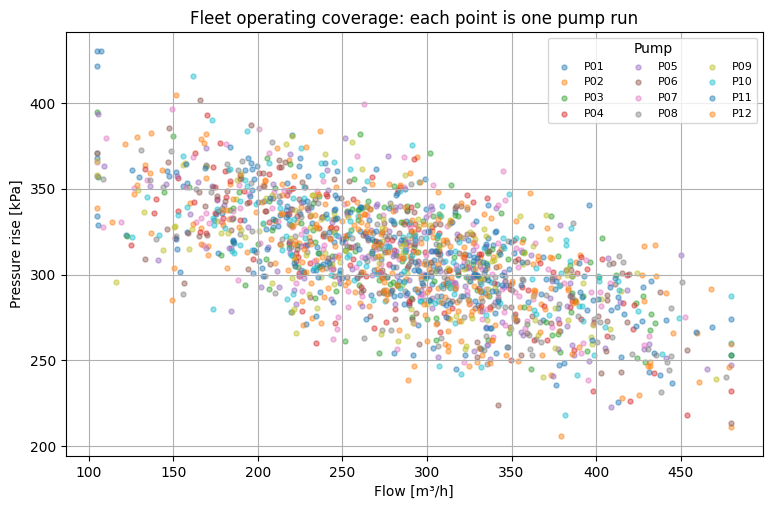

In [ ]:
data_dictionary = pd.DataFrame({
    "field": [
        "event_id", "timestamp", "pump_id", "flow_m3h", "pressure_rise_kpa",
        "inlet_temp_c", "vibration_mm_s", "operating_hours", "run_duration_h",
        "post_run_energy_kwh", "mean_power_kw",
    ],
    "meaning": [
        "unique run identifier", "run start", "physical asset", "inlet flow",
        "pressure increase", "fluid temperature", "vibration RMS", "asset age",
        "completed run duration", "metered energy after run", "prediction target",
    ],
    "units": [
        "—", "datetime", "—", "m³/h", "kPa", "°C", "mm/s", "h", "h", "kWh", "kW"
    ],
    "available_at_start": [
        True, True, True, True, True, True, True, True, False, False, False
    ],
})

display(data_dictionary)

fig, ax = plt.subplots(figsize=(9, 5.5))
for pump_id, group in reference_data.groupby("pump_id"):
    ax.scatter(group["flow_m3h"], group["pressure_rise_kpa"], s=13, alpha=0.45, label=pump_id)
ax.set(
    xlabel="Flow [m³/h]",
    ylabel="Pressure rise [kPa]",
    title="Fleet operating coverage: each point is one pump run",
)
ax.grid(True)
ax.legend(ncol=3, fontsize=8, title="Pump")
plt.show()


### 🧠 What coverage means

A row count alone is not enough. These observations are clustered within twelve pumps,
so 1,680 runs do not represent 1,680 independent assets. Coverage must be checked against
the intended deployment dimensions: pumps, time, flow, pressure, temperature, wear and
operating mode.


## 📂 5.6.3 Audit before modelling

Start with structure and provenance, then investigate values. Automated rules can flag
records for review, but they cannot decide whether an observation is a valid rare event or
an error.

The limits below are **teaching assumptions from the fictional sensor specification**.
They are not universal pump limits.


,check,count
0,received rows,1860
1,unique event IDs,1680
2,duplicate uploads,180
3,missing inlet temperature,47
4,missing vibration,77
5,flow outside 100–500 m³/h,7
6,temperature outside 5–45 °C,6


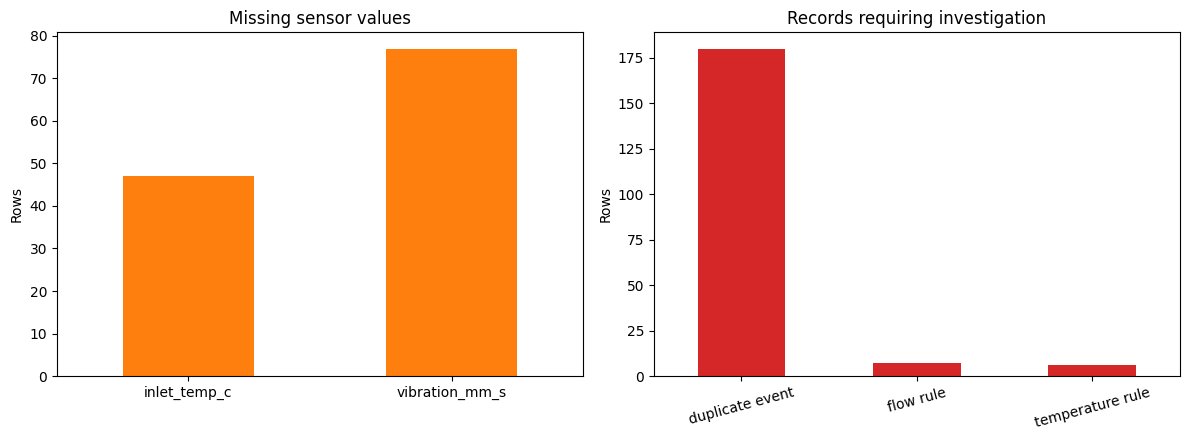

In [ ]:
audit_summary = pd.DataFrame({
    "check": [
        "received rows", "unique event IDs", "duplicate uploads",
        "missing inlet temperature", "missing vibration",
        "flow outside 100–500 m³/h", "temperature outside 5–45 °C",
    ],
    "count": [
        len(received_data),
        received_data["event_id"].nunique(),
        received_data.duplicated("event_id").sum(),
        received_data["inlet_temp_c"].isna().sum(),
        received_data["vibration_mm_s"].isna().sum(),
        (~received_data["flow_m3h"].between(100, 500)).sum(),
        (~received_data["inlet_temp_c"].between(5, 45) & received_data["inlet_temp_c"].notna()).sum(),
    ],
})
display(audit_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
missing_counts = received_data.isna().sum().loc[["inlet_temp_c", "vibration_mm_s"]]
missing_counts.plot.bar(ax=axes[0], color="tab:orange")
axes[0].set(title="Missing sensor values", ylabel="Rows", xlabel="")
axes[0].tick_params(axis="x", rotation=0)

flag_counts = audit_summary.set_index("check").loc[
    ["duplicate uploads", "flow outside 100–500 m³/h", "temperature outside 5–45 °C"],
    "count",
]
flag_counts.index = ["duplicate event", "flow rule", "temperature rule"]
flag_counts.plot.bar(ax=axes[1], color="tab:red")
axes[1].set(title="Records requiring investigation", ylabel="Rows", xlabel="")
axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()


### ⚠️ Do not automatically delete every outlier

The seven low flow values and six high temperature values are unit-entry errors because
we know how they were generated. In practice, confirm this using source records, sensor
metadata or the data owner. A rare high-vibration run may be the failure condition the
model most needs to learn.

A defensible audit records the rule, the evidence, the action and the number of affected
rows. Silent deletion makes the analysis impossible to reproduce.


## 📂 5.6.4 Duplicates can cross the split boundary

Repeated uploads do not create new evidence. If copies of the same event appear in both
training and validation data, the model is evaluated on an event it has effectively
already seen.


,quantity,count
0,training rows,1395
1,validation rows,465
2,event IDs appearing in both,93
3,validation rows whose event also appears in tr...,93


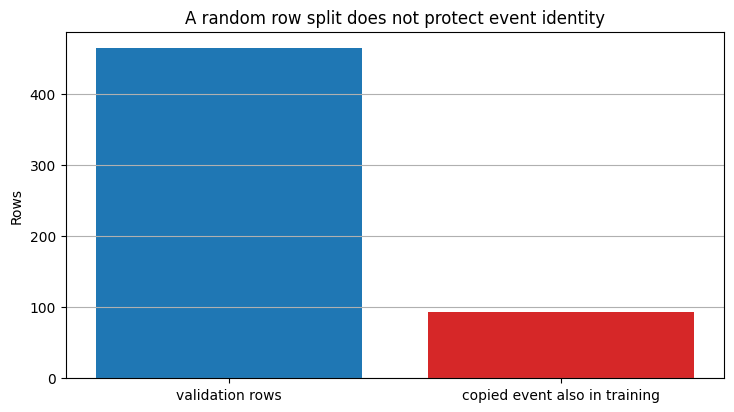

In [ ]:
train_received, validation_received = train_test_split(
    received_data, test_size=0.25, random_state=56
)
shared_events = set(train_received["event_id"]) & set(validation_received["event_id"])

duplicate_split_summary = pd.DataFrame({
    "quantity": [
        "training rows", "validation rows", "event IDs appearing in both",
        "validation rows whose event also appears in training",
    ],
    "count": [
        len(train_received), len(validation_received), len(shared_events),
        validation_received["event_id"].isin(shared_events).sum(),
    ],
})
display(duplicate_split_summary)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(
    ["validation rows", "copied event also in training"],
    [len(validation_received), validation_received["event_id"].isin(shared_events).sum()],
    color=["tab:blue", "tab:red"],
)
ax.set(ylabel="Rows", title="A random row split does not protect event identity")
ax.grid(True, axis="y")
plt.show()


**Selection action:** retain one verified record per `event_id` before splitting. If
repeated measurements are scientifically meaningful rather than accidental copies, keep
them but assign a group identifier so related observations remain together.


## 📂 5.6.5 Target leakage: information from the future

`post_run_energy_kwh` is highly predictive because it is measured over the completed run.
Combined with run duration, it nearly reconstructs the target:

$$
\text{mean power} \approx \frac{\text{post-run energy}}{\text{run duration}}.
$$

That information does not exist at the start of the run. Using it would answer a different
question from the prediction contract.


,MAE_kW,R2
feature set,,
available at prediction time,1.748,0.942
includes post-run leakage,0.448,0.993


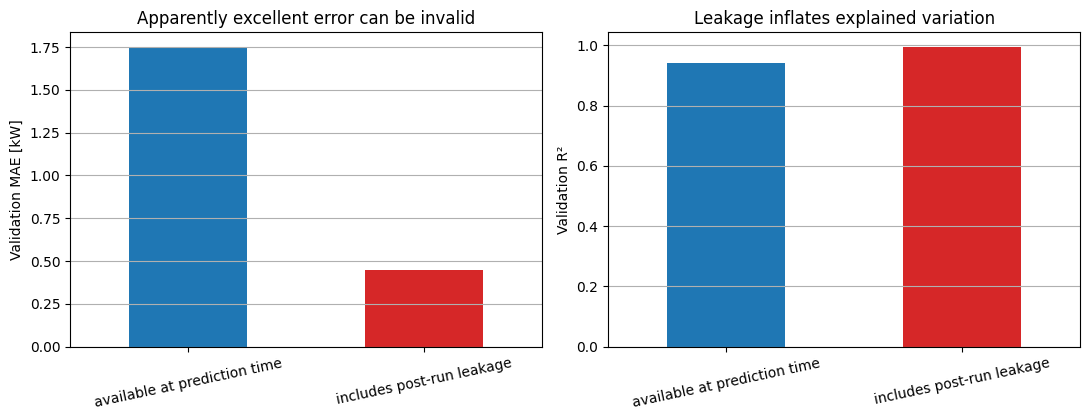

In [ ]:
modelling_data = reference_data.drop_duplicates("event_id").copy()
train_index, validation_index = train_test_split(
    modelling_data.index, test_size=0.25, random_state=5605
)

clean_features = [
    "flow_m3h", "pressure_rise_kpa", "inlet_temp_c", "vibration_mm_s", "operating_hours"
]
leaky_features = clean_features + ["run_duration_h", "post_run_energy_kwh"]

def numeric_svr(feature_names):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", SVR(C=80, epsilon=0.2, gamma="scale")),
    ])

leakage_results = []
for label, feature_names in {
    "available at prediction time": clean_features,
    "includes post-run leakage": leaky_features,
}.items():
    model = numeric_svr(feature_names)
    model.fit(modelling_data.loc[train_index, feature_names], modelling_data.loc[train_index, "mean_power_kw"])
    prediction = model.predict(modelling_data.loc[validation_index, feature_names])
    leakage_results.append({
        "feature set": label,
        "MAE_kW": mean_absolute_error(modelling_data.loc[validation_index, "mean_power_kw"], prediction),
        "R2": r2_score(modelling_data.loc[validation_index, "mean_power_kw"], prediction),
    })

leakage_results = pd.DataFrame(leakage_results).set_index("feature set")
display(leakage_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
leakage_results["MAE_kW"].plot.bar(ax=axes[0], color=["tab:blue", "tab:red"])
leakage_results["R2"].plot.bar(ax=axes[1], color=["tab:blue", "tab:red"])
axes[0].set(title="Apparently excellent error can be invalid", ylabel="Validation MAE [kW]", xlabel="")
axes[1].set(title="Leakage inflates explained variation", ylabel="Validation R²", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=12)
    ax.grid(True, axis="y")
fig.tight_layout()
plt.show()


### 🧠 Why a better score can be worse evidence

The leaky model has an impressive validation score but cannot be operated as specified.
Leakage is a **timeline and availability problem**, not merely a suspicious column name.
Ask when and how every feature is produced.

Other leakage examples include a maintenance outcome entered after inspection, a target
encoded inside a status code, or preprocessing fitted using the validation or test rows.


## 📂 5.6.6 The split must match the deployment question

There is no universally correct split.

* **Random row split:** performance on new runs from the represented fleet under similar
  conditions.
* **Grouped split by pump:** transfer to pumps absent from training.
* **Time-ordered split:** performance on later operation using only earlier evidence.

We include `pump_id` because identity may legitimately capture persistent differences when
predicting future runs for known pumps. It cannot help with a previously unseen identity.


In [ ]:
numeric_features = [
    "flow_m3h", "pressure_rise_kpa", "inlet_temp_c", "vibration_mm_s", "operating_hours"
]
categorical_features = ["pump_id"]

preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("asset", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

pump_model = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", SVR(C=80, epsilon=0.25, gamma="scale")),
])

X = modelling_data[numeric_features + categorical_features]
y = modelling_data["mean_power_kw"]
groups = modelling_data["pump_id"]

random_train, random_test = train_test_split(
    np.arange(len(modelling_data)), test_size=0.25, random_state=5606
)
grouped_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=5606)
group_train, group_test = next(grouped_split.split(X, y, groups=groups))
ordered = np.argsort(modelling_data["timestamp"].to_numpy())
time_boundary = int(0.75 * len(ordered))
time_train, time_test = ordered[:time_boundary], ordered[time_boundary:]

split_indices = {
    "random rows": (random_train, random_test),
    "unseen pumps": (group_train, group_test),
    "future period": (time_train, time_test),
}

split_results = []
fitted_split_models = {}
for split_name, (train_rows, test_rows) in split_indices.items():
    fitted = clone(pump_model).fit(X.iloc[train_rows], y.iloc[train_rows])
    prediction = fitted.predict(X.iloc[test_rows])
    fitted_split_models[split_name] = fitted
    split_results.append({
        "split": split_name,
        "train_rows": len(train_rows),
        "validation_rows": len(test_rows),
        "shared_pumps": len(set(groups.iloc[train_rows]) & set(groups.iloc[test_rows])),
        "MAE_kW": mean_absolute_error(y.iloc[test_rows], prediction),
        "RMSE_kW": root_mean_squared_error(y.iloc[test_rows], prediction),
        "R2": r2_score(y.iloc[test_rows], prediction),
    })

split_results = pd.DataFrame(split_results).set_index("split")
split_results


,train_rows,validation_rows,shared_pumps,MAE_kW,RMSE_kW,R2
split,,,,,,
random rows,1260,420,12,1.445,1.899,0.960
unseen pumps,1260,420,0,2.423,3.233,0.885
future period,1260,420,12,1.821,2.357,0.833


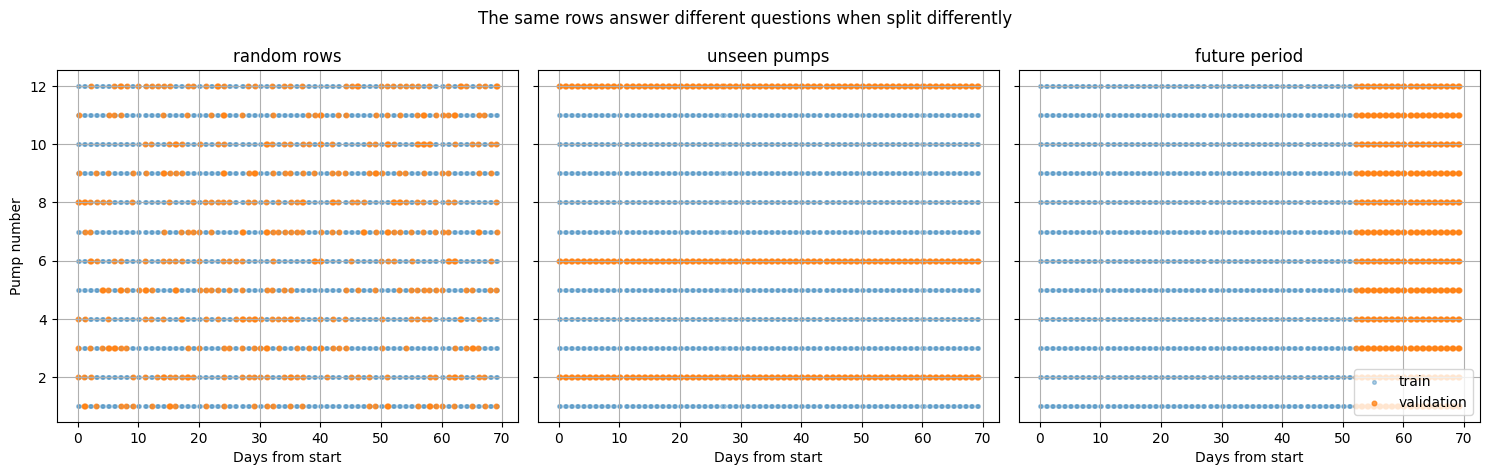

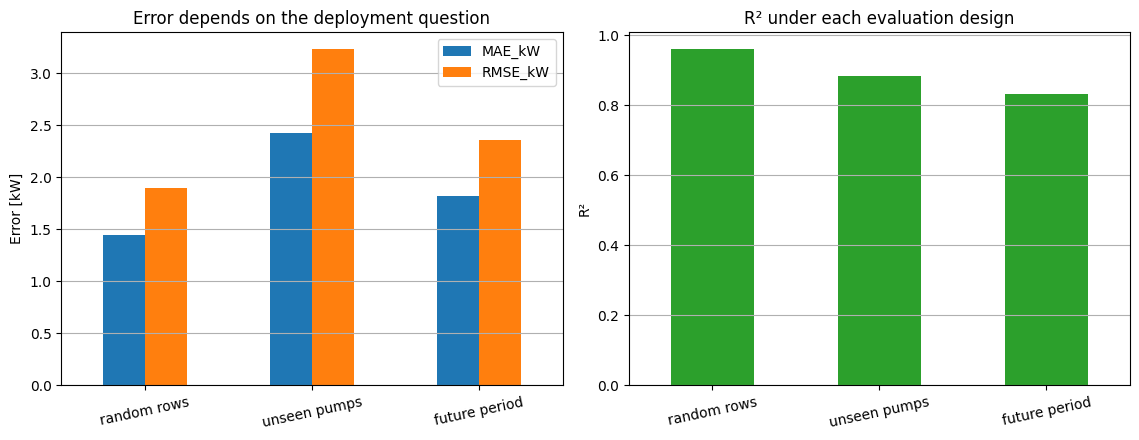

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
pump_number = modelling_data["pump_id"].str[1:].astype(int)
days_from_start = (modelling_data["timestamp"] - modelling_data["timestamp"].min()).dt.total_seconds() / 86400

for ax, (split_name, (train_rows, test_rows)) in zip(axes, split_indices.items()):
    ax.scatter(days_from_start.iloc[train_rows], pump_number.iloc[train_rows], s=7, alpha=0.35, label="train")
    ax.scatter(days_from_start.iloc[test_rows], pump_number.iloc[test_rows], s=11, alpha=0.75, label="validation")
    ax.set(title=split_name, xlabel="Days from start")
    ax.grid(True)
axes[0].set_ylabel("Pump number")
axes[-1].legend(loc="lower right")
fig.suptitle("The same rows answer different questions when split differently")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
split_results[["MAE_kW", "RMSE_kW"]].plot.bar(ax=axes[0])
split_results["R2"].plot.bar(ax=axes[1], color="tab:green")
axes[0].set(title="Error depends on the deployment question", ylabel="Error [kW]", xlabel="")
axes[1].set(title="R² under each evaluation design", ylabel="R²", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=12)
    ax.grid(True, axis="y")
fig.tight_layout()
plt.show()


### 🧠 Interpreting the three results

The random split is easiest because the same pumps and dates occur on both sides. The
grouped result estimates transfer to unseen pumps, while the time split tests later
operation after wear and seasonal conditions have changed.

A lower random-split error is not dishonest if the real task is another run from these
same pumps. It becomes misleading when it is reported as evidence for unseen assets or
future conditions. State the split question beside every score.


### Optional interactive split explorer

Run the cell and use the dropdown to inspect one evaluation design at full size. The
figure and summary update without changing any code. If widgets are unavailable, the cell
displays the grouped split as a static fallback.


In [ ]:
def show_split(split_name="unseen pumps"):
    train_rows, validation_rows = split_indices[split_name]
    train_pumps = set(groups.iloc[train_rows])
    validation_pumps = set(groups.iloc[validation_rows])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(
        days_from_start.iloc[train_rows], pump_number.iloc[train_rows],
        s=12, alpha=0.35, label="training rows"
    )
    ax.scatter(
        days_from_start.iloc[validation_rows], pump_number.iloc[validation_rows],
        s=20, alpha=0.8, label="validation rows"
    )
    ax.set(
        xlabel="Days from start", ylabel="Pump number",
        title=f"{split_name}: {len(train_pumps & validation_pumps)} pumps shared across subsets",
    )
    ax.set_yticks(range(1, n_pumps + 1))
    ax.grid(True)
    ax.legend()
    plt.show()

    return pd.Series({
        "training pumps": len(train_pumps),
        "validation pumps": len(validation_pumps),
        "shared pumps": len(train_pumps & validation_pumps),
        "validation MAE [kW]": split_results.loc[split_name, "MAE_kW"],
    }, name=split_name).to_frame()


try:
    from ipywidgets import Dropdown, interact

    interact(
        show_split,
        split_name=Dropdown(
            options=list(split_indices),
            value="unseen pumps",
            description="Split:",
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the grouped split.")
    show_split("unseen pumps")


interactive(children=(Dropdown(description='Split:', index=1, options=('random rows', 'unseen pumps', 'future …

## 📂 5.6.7 Why one future holdout may not be enough

Section 5.6.6 used one chronological split: train on the first 75% of runs and validate on
the final 25%. That answers an important question, but the result depends on one date
boundary.

**Time-aware cross-validation** repeats the check at several historical boundaries. For
each fold, the model learns only from earlier runs and is evaluated on the next block of
later runs. This helps answer:

> Was the model consistently useful as time moved forward, or was the result unusually
> good or bad during one period?

Ordinary shuffled K-fold validation is unsuitable for this question because it can place
later runs in training while earlier runs are used for validation.


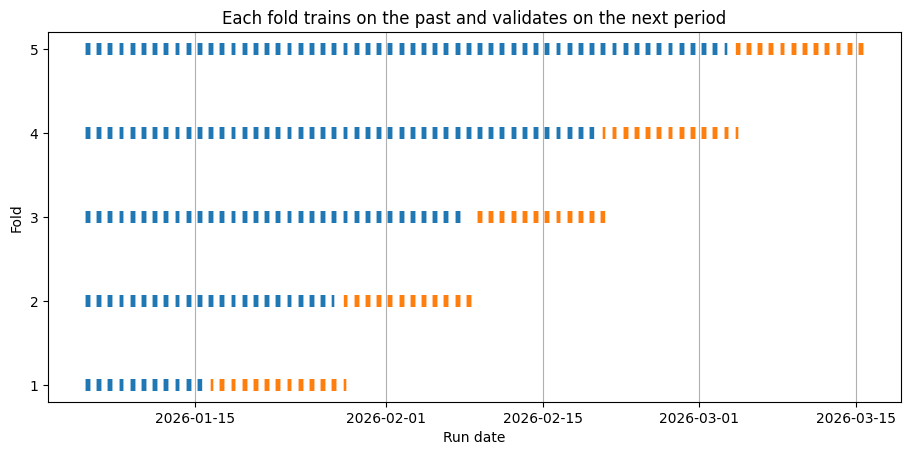

,fold,train_end,validation_start
0,1,2026-01-15 12:00:00,2026-01-16 12:00:00
1,2,2026-01-27 08:00:00,2026-01-28 08:00:00
2,3,2026-02-07 12:00:00,2026-02-09 08:00:00
3,4,2026-02-19 12:00:00,2026-02-20 12:00:00
4,5,2026-03-03 08:00:00,2026-03-04 08:00:00


In [ ]:
time_order = np.argsort(modelling_data["timestamp"].to_numpy())
time_cv = TimeSeriesSplit(n_splits=5, gap=24)

fig, ax = plt.subplots(figsize=(11, 4.8))
split_table = []
for fold, (train_relative, validation_relative) in enumerate(time_cv.split(time_order), start=1):
    train_rows = time_order[train_relative]
    validation_rows = time_order[validation_relative]
    ax.scatter(
        modelling_data.iloc[train_rows]["timestamp"],
        np.full(len(train_rows), fold),
        marker="|", s=70, color="tab:blue",
    )
    ax.scatter(
        modelling_data.iloc[validation_rows]["timestamp"],
        np.full(len(validation_rows), fold),
        marker="|", s=70, color="tab:orange",
    )
    split_table.append({
        "fold": fold,
        "train_end": modelling_data.iloc[train_rows]["timestamp"].max(),
        "validation_start": modelling_data.iloc[validation_rows]["timestamp"].min(),
    })

ax.set(xlabel="Run date", ylabel="Fold", title="Each fold trains on the past and validates on the next period")
ax.set_yticks(range(1, 6))
ax.grid(True, axis="x")
plt.show()
pd.DataFrame(split_table)


### 🧠 Reading the figure

Each horizontal row is one fold:

* **blue marks:** runs available for training at that historical point;
* **blank space after blue:** a 24-row gap, used so immediately adjacent runs are not split
  across training and validation;
* **orange marks:** the next period used for validation; and
* later folds contain more historical training data.

Use this approach when the deployment question concerns **future operation**, such as
equipment wear, seasonal demand or sensor drift. It does not replace grouping by pump when
the question concerns transfer to unseen assets.

`TimeSeriesSplit` preserves row order; it does not read the timestamp column itself. We
therefore sort by `timestamp` first. If observations are irregularly spaced, define
engineering date boundaries instead of assuming equal row counts represent equal periods.


## 📂 5.6.8 Why preprocessing belongs inside the pipeline

Preprocessing can look like harmless data cleaning, but some steps **learn from the
dataset**:

* median imputation learns a replacement value for each feature;
* standardisation learns each feature's mean and scale; and
* one-hot encoding learns which pump identities exist.

If these quantities are calculated using all rows before splitting, the validation data
has influenced model preparation. That is a quieter form of leakage.

Our `pump_model` avoids this: each call to `fit` learns imputation values, means, scales,
asset encoding and model parameters from the supplied training rows only. Calling
`predict` reuses those learned transformations without refitting them.


In [ ]:
random_model = fitted_split_models["random rows"]
numeric_pipeline = random_model.named_steps["preprocessing"].named_transformers_["numeric"]
learned_values = pd.DataFrame({
    "feature": numeric_features,
    "imputation_median": numeric_pipeline.named_steps["imputer"].statistics_,
    "scaling_mean": numeric_pipeline.named_steps["scaler"].mean_,
    "scaling_scale": numeric_pipeline.named_steps["scaler"].scale_,
})
learned_values


,feature,imputation_median,scaling_mean,scaling_scale
0,flow_m3h,286.354,284.722,77.365
1,pressure_rise_kpa,310.338,310.277,31.653
2,inlet_temp_c,22.852,22.948,5.157
3,vibration_mm_s,1.354,1.351,0.226
4,operating_hours,1228.878,1260.279,405.656


### What the table shows

These values were learned from the random split's **training rows**, not typed in by the
engineer and not calculated from the validation rows. The pipeline stores them and applies
the same values when making validation or future predictions.

### Safe order of operations

1. Reserve the final test set according to the deployment question.
2. Define a pipeline containing every learned preprocessing step.
3. Fit or cross-validate the whole pipeline using development data.
4. Make modelling choices without consulting the final test result.
5. Fit the selected pipeline and evaluate the final test set once.

Fixed engineering conversions may occur before splitting if they use only declared units
and no learned dataset statistics. Their code and assumptions still need documentation.


## 📂 5.6.9 Does the future look like the training data?

Even with a correct time split, we need to compare the earlier training conditions with
the later validation conditions.

Two related checks are useful:

* **Range coverage:** are future values outside the minimum and maximum observed during
  training? If so, the model is extrapolating for that feature.
* **Distribution shift:** are values still inside the old range but concentrated in
  different regions? For example, the future period may contain many more low-flow runs.

The table checks ranges; the histograms show how frequently different values occur.


,training_min,training_max,future_below_training,future_above_training,training_mean,future_mean
feature,,,,,,
flow_m3h,105.000,480.000,0,0,299.962,237.855
pressure_rise_kpa,205.706,430.000,0,0,306.041,322.272
inlet_temp_c,9.942,34.003,0,0,24.520,18.270
vibration_mm_s,0.553,2.146,0,0,1.332,1.387
operating_hours,439.626,2038.689,0,35,1204.889,1432.714


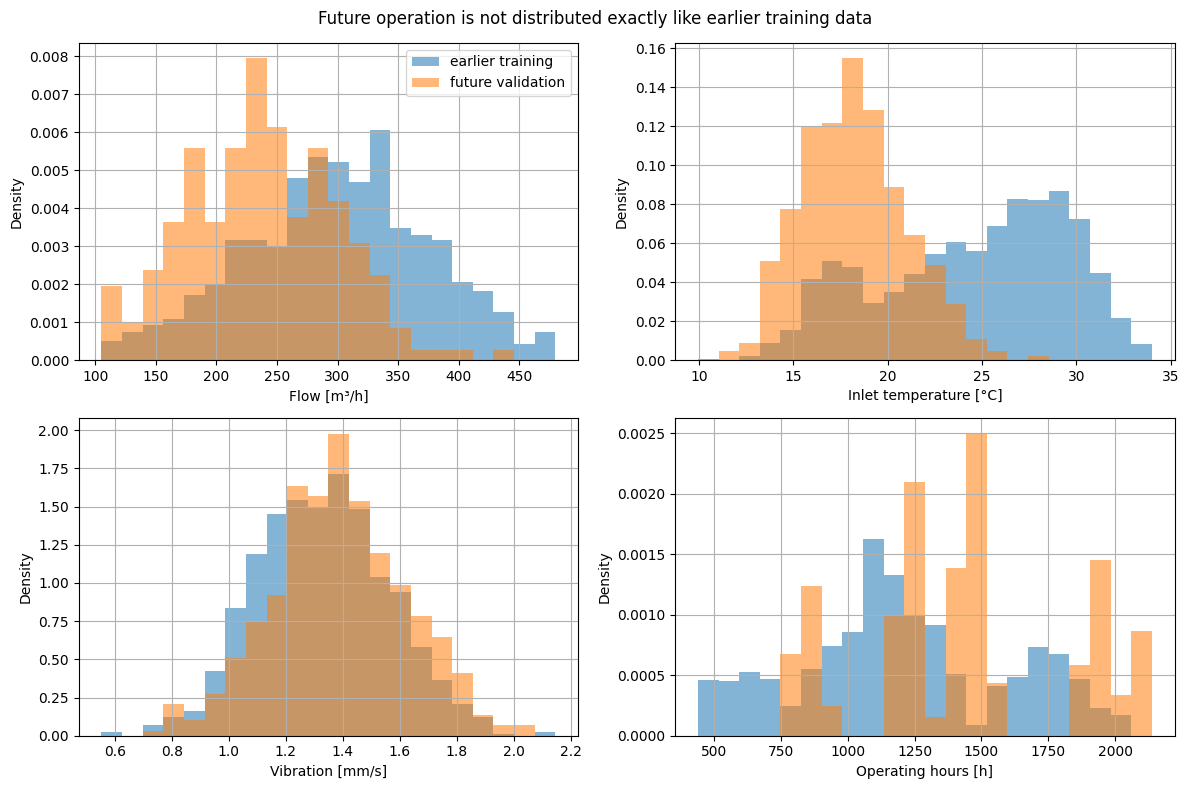

In [ ]:
time_train_data = modelling_data.iloc[time_train]
time_test_data = modelling_data.iloc[time_test]

coverage_summary = []
for feature in numeric_features:
    training_min = time_train_data[feature].min()
    training_max = time_train_data[feature].max()
    future_values = time_test_data[feature]
    coverage_summary.append({
        "feature": feature,
        "training_min": training_min,
        "training_max": training_max,
        "future_below_training": (future_values < training_min).sum(),
        "future_above_training": (future_values > training_max).sum(),
        "training_mean": time_train_data[feature].mean(),
        "future_mean": future_values.mean(),
    })
coverage_summary = pd.DataFrame(coverage_summary).set_index("feature")
display(coverage_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plotted_features = ["flow_m3h", "inlet_temp_c", "vibration_mm_s", "operating_hours"]
labels = ["Flow [m³/h]", "Inlet temperature [°C]", "Vibration [mm/s]", "Operating hours [h]"]
for ax, feature, label in zip(axes.ravel(), plotted_features, labels):
    train_values = time_train_data[feature].dropna()
    future_values = time_test_data[feature].dropna()
    bins = np.histogram_bin_edges(pd.concat([train_values, future_values]), bins=22)
    ax.hist(train_values, bins=bins, density=True, alpha=0.55, label="earlier training")
    ax.hist(future_values, bins=bins, density=True, alpha=0.55, label="future validation")
    ax.set(xlabel=label, ylabel="Density")
    ax.grid(True)
axes[0, 0].legend()
fig.suptitle("Future operation is not distributed exactly like earlier training data")
fig.tight_layout()
plt.show()


### 🧠 Reading the result

In this example, the future period contains lower flow and temperature on average, while
pumps have accumulated more operating hours. Thirty-five future runs also exceed the
largest operating-hours value in training. This helps explain why the future-period score
differs from the random-row score.

A changed distribution does not prove that every prediction is wrong. It tells us that the
model is being asked to work under a different mix of conditions and deserves closer
evaluation.

After deployment, record inputs using the same units and definitions as training. If the
live system calculates a feature differently from the training process, this is called
**training-serving skew**.


## 📂 5.6.10 Turn the audit into data-selection decisions

An audit is useful only if it leads to explicit actions. For every issue, record what will
be kept, corrected, excluded or evaluated separately—and why. A transparent selection
record for this example could state:

| Item | Decision | Reason |
|---|---|---|
| Unit of observation | One verified pump run | Matches the operational decision |
| Duplicate uploads | Keep one row per `event_id` | Copies are not new evidence |
| Unit-rule failures | Quarantine pending source verification | Values conflict with the declared schema |
| Missing sensors | Retain; impute within each training fit | Missingness is limited and occurs in service |
| Post-run energy and duration | Exclude from inputs | Unavailable at prediction time |
| Pump identity | Use only for the represented-fleet task | Unknown categories cannot characterise a new pump |
| Primary evaluation | Time-ordered holdout | Future operation is the main deployment concern |
| Transfer evaluation | Grouped holdout by pump | Separately tests unseen assets |

Changing the intended use may change the correct decisions. For example, a model deployed
only after a run could legitimately use metered run energy, but it would no longer be the
model defined in Section 5.6.1.


## 📂 5.6.11 Why the selection record must be saved

A reported model score is difficult to interpret unless another engineer can determine
which evidence produced it. The selection record should allow someone to:

* reproduce the dataset used for modelling;
* understand why rows and features were included or excluded; and
* decide whether the model is relevant to a new pump, site or operating period.

At minimum, record:

* data owner, source system and extraction date;
* row definition, target definition and prediction time;
* feature names, types, units and availability;
* asset, site and time coverage;
* missingness, duplicate and validity-rule results;
* every inclusion, exclusion or correction rule;
* split strategy, group key, date boundary and random seed;
* software versions and preprocessing pipeline; and
* known limitations, unsupported regions and monitoring plan.

Version the selection code and retain immutable raw data where governance permits. A
cleaned file without its provenance is difficult to audit.


In [ ]:
selection_record = {
    "dataset": "synthetic pump-fleet teaching data",
    "prediction_time": "start of run",
    "target": "mean_power_kw",
    "raw_rows_received": len(received_data),
    "verified_unique_events": modelling_data["event_id"].nunique(),
    "group_key": "pump_id",
    "time_field": "timestamp",
    "random_seed": 5606,
    "excluded_inputs": ["run_duration_h", "post_run_energy_kwh"],
    "primary_split": "chronological 75% / 25%",
    "secondary_split": "GroupShuffleSplit by pump",
}

pd.Series(selection_record, name="documented value").to_frame()


,documented value
dataset,synthetic pump-fleet teaching data
prediction_time,start of run
target,mean_power_kw
raw_rows_received,1860
verified_unique_events,1680
group_key,pump_id
time_field,timestamp
random_seed,5606
excluded_inputs,"[run_duration_h, post_run_energy_kwh]"
primary_split,chronological 75% / 25%


## 📂 5.6.12 Optional code reference

You do not need to memorise every function below. Use this table when choosing the code
that implements a data-selection decision.

| Tool | Purpose in this notebook |
|---|---|
| `DataFrame.isna`, `duplicated`, `between` | Audit missingness, identity and validity rules |
| `train_test_split` | Random row holdout for exchangeable samples |
| `GroupShuffleSplit` | Keep physical assets separated across a holdout |
| `TimeSeriesSplit` | Preserve the direction of time across validation folds |
| `SimpleImputer` | Learn replacement values from training data |
| `OneHotEncoder(handle_unknown="ignore")` | Encode known identities without crashing on unseen ones |
| `ColumnTransformer` | Apply appropriate transformations to different columns |
| `Pipeline` | Fit preprocessing and the regressor as one auditable object |
| `clone` | Create an unfitted copy of an estimator for a fair comparison |

These functions automate mechanics. They do not decide whether a pump, date, field or
validity rule represents the intended use.


## 📂 5.6.13 Putting the complete workflow together

1. Answer the five task questions and write the prediction contract.
2. Establish row identity, schema, units and provenance.
3. Investigate missing values, duplicates and implausible observations.
4. Remove features unavailable at prediction time.
5. Select a split that represents the real generalisation question.
6. Fit all learned preprocessing inside a pipeline.
7. Compare coverage and performance across assets, time and operating regions.
8. Document decisions and plan monitoring for shift.

**Central idea:** a score on withheld rows is not enough by itself. Those rows must be
separated in the way deployment requires, use only information available at prediction
time, and represent the conditions where the result will be used.


## 📚 References

The linked scikit-learn documentation describes leakage-safe pipelines and splitters for
independent, grouped and time-ordered observations. Google’s engineering guidance
emphasises measuring training-serving skew and evaluating on later data. The NIST AI RMF
Playbook provides broader guidance on data representativeness, quality, documentation and
monitoring.

## 🤖 AI Acknowledgment

Generative AI assisted with drafting, code development and editorial review. The teaching
design, equations, code behaviour and source alignment were checked for this unit. The pump
dataset is synthetic and must not be interpreted as measured equipment performance.
